# Домашнее задание: SFT для function calling

Qwen2.5-0.5B-Instruct умеет вызывать функции в формате `<tool_call>`, но наши пять функций умного дома видит
впервые и обращается с ними вольно. Дообучим её целиком (все веса) на диалогах с умным домом
и в конце посмотрим, как она управляет симулятором.

| Блок | Баллы |
|---|---|
| 1. До обучения: генерация через chat template | 1 |
| 2. Данные: разбор примера и роль каждого сообщения | 2 |
| 3. Маска loss: теги `{% generation %}` в шаблоне | 2 |
| 4. Обучение | 3 |
| 5. Оценка на тест-сете (дано) | 0 |
| 6. Агентный цикл | 2 |

Дано и менять не нужно: `smart_home.py` (симулятор и схемы пяти функций), `chat_ui.py` (чат),
`data/` с `train.jsonl`, `validation.jsonl` и `test_cases.jsonl`.
Ячейки для заполнения помечены `YOUR CODE HERE`.

## 0. Окружение

Берём Instruct-модель: формат `<tool_call>` и токен конца реплики `<|im_end|>` она уже знает,
учить будем поведению с конкретными функциями.

In [1]:
# %pip install transformers==4.56.1 trl==0.23.1 datasets==3.6.0 accelerate==1.6.0 ipywidgets==8.1.9 matplotlib==3.10.1 pandas==2.2.3
import gc
import json
import re
import time
import hashlib
import importlib.metadata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

from chat_ui import launch_chat
from smart_home import BASELINE_PROMPTS, SMART_HOME_TOOLS, SYSTEM_PROMPT, SmartHome

SEED = 42
MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
OUTPUT_DIR = Path("outputs/full_sft")
MAX_LENGTH = 2048

set_seed(SEED)
assert torch.cuda.is_available(), "Нужен GPU kernel"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, dtype=torch.bfloat16, attn_implementation="sdpa").to("cuda")
print("GPU:", torch.cuda.get_device_name())
print("Model:", MODEL_NAME, "revision:", MODEL_REVISION)
print("Parameters:", sum(p.numel() for p in model.parameters()))
assert all(p.requires_grad for p in model.parameters()), "Full SFT must update all weights"


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

GPU: NVIDIA A100 80GB PCIe
Model: Qwen/Qwen2.5-0.5B-Instruct revision: 7ae557604adf67be50417f59c2c2f167def9a775
Parameters: 494032768


## 1. До обучения · 1 балл

Функция для модели — это JSON Schema: имя, описание, аргументы с типами и ограничениями.
Схемы передаются в `apply_chat_template` параметром `tools`: шаблон вставит их в system-реплику
и объяснит модели формат ответа `<tool_call>`. Посмотрим, что именно получает модель на вход.

In [2]:
print(json.dumps(SMART_HOME_TOOLS[0], ensure_ascii=False, indent=2))
print("=" * 80)
messages = [
    {"role": "system", "content": SYSTEM_PROMPT},
    {"role": "user", "content": "Turn on the kitchen light."},
]
print(tokenizer.apply_chat_template(messages, tools=SMART_HOME_TOOLS, tokenize=False, add_generation_prompt=True))

{
  "type": "function",
  "function": {
    "name": "turn_light",
    "description": "Switch a room light on or off. Ask for the room if unknown.",
    "parameters": {
      "type": "object",
      "properties": {
        "room": {
          "type": "string",
          "enum": [
            "kitchen",
            "bedroom",
            "living_room"
          ]
        },
        "state": {
          "type": "string",
          "enum": [
            "on",
            "off"
          ]
        }
      },
      "required": [
        "room",
        "state"
      ],
      "additionalProperties": false
    }
  }
}
<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"n

**Задание (1 балл).** Напишите `generate`: сообщения и схемы функций проходят через `apply_chat_template`
с `add_generation_prompt=True`, декодирование жадное, стоп на `<|im_end|>` (это `eos_token` токенизатора).
Верните только новые токены, без спецтокенов. Эта функция используется во всех следующих блоках.

In [3]:
def generate(model, tokenizer, messages, tools, max_new_tokens=256):
    model.eval()
    inputs = tokenizer.apply_chat_template(
        messages, tools=tools, tokenize=True, add_generation_prompt=True,
        return_tensors="pt", return_dict=True,
    ).to(model.device)
    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=max_new_tokens, do_sample=False,
            eos_token_id=tokenizer.eos_token_id,
            pad_token_id=tokenizer.pad_token_id, use_cache=True,
        )
    new_tokens = generated[0, inputs["input_ids"].shape[1]:]
    return tokenizer.decode(new_tokens, skip_special_tokens=True)


def answer(model, tokenizer, prompt):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": prompt}]
    return generate(model, tokenizer, messages, SMART_HOME_TOOLS)


Формат модель знает, поэтому простые запросы отработает правильно. Смотрите на сложные: «Open the garage» —
модель подставляет в `turn_light` комнату `garage`, которой нет в схеме; «Turn off all lights» — придумывает
`room: "all"` вместо трёх вызовов; «Turn on the light» — выбирает комнату сама вместо уточняющего вопроса.
Запомним её ответы на десять запросов, после обучения сравним.

In [4]:
comparison = pd.DataFrame({"prompt": BASELINE_PROMPTS})
comparison["base"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


,prompt,base
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>"
7,Hello!,How can I help you today?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>"
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>"


## 2. Данные · 2 балла

Чтобы модель вызывала функции, покажем ей диалоги, где это делается правильно.
Одна строка JSONL — один диалог: `messages` и `tools`. Вызов функции — поле `tool_calls`
у реплики assistant, результат функции — отдельное сообщение с ролью `tool`.

In [5]:
def read_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]


def show_dialog(messages):
    for message in messages:
        print(f"[{message['role']}] {message.get('content', '')}")
        for call in message.get("tool_calls") or []:
            arguments = json.dumps(call["function"]["arguments"], ensure_ascii=False)
            print(f"    -> {call['function']['name']}({arguments})")


train_rows = read_jsonl("data/train.jsonl")
validation_rows = read_jsonl("data/validation.jsonl")
print(f"train: {len(train_rows)}, validation: {len(validation_rows)}\n")

example = next(row for row in train_rows if any(m.get("tool_calls") for m in row["messages"]))
show_dialog(example["messages"])

train: 831, validation: 91

[system] You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.
[user] Сделай в гостиной 40 градусов, гости мерзнут
[assistant] Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?
[user] Хорошо, тогда максимум
[assistant] 
    -> set_temperature({"room": "living_room", "value": 30})
[tool] {"room": "living_room", "light": "off", "temperature": 30}
[assistant] Готово, в гостиной теперь 30 градусов.


В данных четыре типа диалогов. Примеры без вызова — не балласт: это единственное место, где модель видит,
что на неподдерживаемый запрос («открой гараж», «какая погода») нужно ответить отказом, а не подобрать
ближайшую функцию.

In [6]:
def scenario_type(row):
    calls_per_message = [len(m.get("tool_calls") or []) for m in row["messages"]]
    if sum(calls_per_message) == 0:
        return "no_call"
    if sum(n > 0 for n in calls_per_message) > 1:
        return "multi_turn"
    return "parallel_calls" if max(calls_per_message) > 1 else "single_call"


pd.DataFrame({
    "train": pd.Series([scenario_type(row) for row in train_rows]).value_counts(),
    "validation": pd.Series([scenario_type(row) for row in validation_rows]).value_counts(),
})

,train,validation
multi_turn,219,22
no_call,144,16
parallel_calls,145,15
single_call,323,38


Тот же диалог после шаблона — ровно такой текст модель увидит на обучении. `tool_calls` стали блоками
`<tool_call>` внутри реплики assistant, а результат функции — блоком `<tool_response>` внутри реплики
**user**: для модели это входящая информация, как и вопрос пользователя.

In [7]:
print(tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False))

<|im_start|>system
You are a smart home assistant. Use only the provided tools. Do not invent missing arguments or claim actions without tool results. Ask for clarification when needed.

# Tools

You may call one or more functions to assist with the user query.

You are provided with function signatures within <tools></tools> XML tags:
<tools>
{"type": "function", "function": {"name": "turn_light", "description": "Switch a room light on or off. Ask for the room if unknown.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "bedroom", "living_room"]}, "state": {"type": "string", "enum": ["on", "off"]}}, "required": ["room", "state"], "additionalProperties": false}}}
{"type": "function", "function": {"name": "set_temperature", "description": "Set an absolute room temperature in Celsius. For relative changes, obtain the current temperature first.", "parameters": {"type": "object", "properties": {"room": {"type": "string", "enum": ["kitchen", "

### Разбор данных

Результат функции — внешнее наблюдение, которое модель получает после выполнения вызова. В шаблоне Qwen сообщения `tool` помещаются в `<tool_response>` внутри входящей реплики `user`: эту информацию нужно прочитать и использовать в следующем ответе. Предсказывать её не требуется. Если включить эти токены в loss, часть обучения будет потрачена на воспроизведение состояния симулятора вместо выбора действия и ответа. Кроме того, модель будет получать сигнал генерировать внешние результаты, которые она должна узнавать из вызова, а не придумывать. Маска исключает их из целевых токенов, но сохраняет в контексте.

| Тип | Train | Validation | Навык и последствия удаления |
|---|---:|---:|---|
| single_call | 323 | 38 | Выбор одной функции и её аргументов, затем ответ по результату. Без этого типа уменьшается число примеров базового соответствия запроса действию. |
| parallel_calls | 145 | 15 | Несколько вызовов в одной реплике: например, свет и температура или свет во всех комнатах. Без них модель может пропускать часть команды или пытаться выразить её одним несуществующим вызовом. |
| multi_turn | 219 | 22 | Последовательные решения по истории и результатам инструментов: прочитать температуру, затем изменить её, понять продолжение команды. Без них недостаточно примеров работы с зависимыми действиями и контекстом. |
| no_call | 144 | 16 | Ответ без инструмента, уточнение недостающих аргументов и отказ от неподдерживаемой команды. Без этих примеров появляется перекос в сторону вызова функции на любой запрос. |

Типы определены функцией `scenario_type` из шаблона, а не вручную по смыслу каждого диалога. Это объяснение ожидаемого обучающего сигнала; отдельные эксперименты с удалением типов данных не проводились.


## 3. Маска loss · 2 балла

В тексте выше модель должна учиться только своим репликам: тексту, `<tool_call>` и `<|im_end|>`.
Запрос пользователя и результат функции она читает, но не предсказывает — у этих токенов label `-100`.
За это в TRL отвечает `assistant_only_loss=True`, а маску он строит по тегам
`{% generation %}…{% endgeneration %}` в chat template. В нативном шаблоне Qwen их нет.

In [8]:
NATIVE_TEMPLATE = tokenizer.chat_template
print(NATIVE_TEMPLATE)

{%- if tools %}
    {{- '<|im_start|>system\n' }}
    {%- if messages[0]['role'] == 'system' %}
        {{- messages[0]['content'] }}
    {%- else %}
        {{- 'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.' }}
    {%- endif %}
    {{- "\n\n# Tools\n\nYou may call one or more functions to assist with the user query.\n\nYou are provided with function signatures within <tools></tools> XML tags:\n<tools>" }}
    {%- for tool in tools %}
        {{- "\n" }}
        {{- tool | tojson }}
    {%- endfor %}
    {{- "\n</tools>\n\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\n<tool_call>\n{\"name\": <function-name>, \"arguments\": <args-json-object>}\n</tool_call><|im_end|>\n" }}
{%- else %}
    {%- if messages[0]['role'] == 'system' %}
        {{- '<|im_start|>system\n' + messages[0]['content'] + '<|im_end|>\n' }}
    {%- else %}
        {{- '<|im_start|>system\nYou are Qwen, created by Alibaba C

**Задание (2 балла).** Оберните в `{% generation %}…{% endgeneration %}` вывод реплик assistant — и текст,
и `tool_calls` — и присвойте результат в `tokenizer.chat_template`. Текст, который рендерит шаблон,
меняться не должен: теги влияют только на маску. Ячейка после задания проверит и то, и другое,
и напечатает токены, по которым будет считаться loss.

In [9]:
def add_assistant_generation_tags(native_template):
    # Separate ordinary assistant replies from the user/system branch.
    condition = '(message.role == "user") or (message.role == "system" and not loop.first) or (message.role == "assistant" and not message.tool_calls)'
    assert native_template.count(condition) == 1, "Unexpected native template"
    template = native_template.replace(
        condition, '(message.role == "user") or (message.role == "system" and not loop.first)'
    )
    assistant_branch = '    {%- elif message.role == "assistant" %}'
    plain_reply = r"""    {%- elif message.role == "assistant" and not message.tool_calls %}
        {{- '<|im_start|>assistant\n' }}
        {%- generation %}
        {{- message.content + '<|im_end|>' }}
        {%- endgeneration %}
        {{- '\n' }}
"""
    assert template.count(assistant_branch) == 1
    template = template.replace(assistant_branch, plain_reply + assistant_branch)
    # Tool calls and optional assistant text share a generation span.
    before, tail = template.split(assistant_branch, 1)
    body, after = tail.split('    {%- elif message.role == "tool" %}', 1)
    header = "{{- '<|im_start|>' + message.role }}"
    ending = r"{{- '<|im_end|>\n' }}"
    assert body.count(header) == body.count(ending) == 1
    body = body.replace(header, header + '\n        {%- generation %}')
    body = body.replace(ending, r"{{- '<|im_end|>' }}" + '\n        {%- endgeneration %}\n        ' + r"{{- '\n' }}")
    return before + assistant_branch + body + '    {%- elif message.role == "tool" %}' + after


TRAIN_TEMPLATE = add_assistant_generation_tags(NATIVE_TEMPLATE)
tokenizer.chat_template = TRAIN_TEMPLATE


In [10]:
rendered = tokenizer.apply_chat_template(example["messages"], tools=example["tools"], tokenize=False)
assert rendered == tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE
), "Теги изменили текст шаблона"

encoded = tokenizer.apply_chat_template(
    example["messages"], tools=example["tools"],
    tokenize=True, return_dict=True, return_assistant_tokens_mask=True,
)
trained = tokenizer.decode([token for token, flag in zip(encoded["input_ids"], encoded["assistant_masks"]) if flag])
assert "<tool_call>" in trained and "<|im_end|>" in trained, "Реплики assistant не попали в маску"
assert "<tools>" not in trained and "<tool_response>" not in trained, "В маске лишние токены"
print(f"учим {sum(encoded['assistant_masks'])} из {len(encoded['input_ids'])} токенов:\n")
print(trained)
mask_audit = []
for split, rows in (("train", train_rows), ("validation", validation_rows)):
    for row in rows:
        text = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False)
        original = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=False, chat_template=NATIVE_TEMPLATE)
        assert text == original, (split, row["id"], "render changed")
        enc = tokenizer.apply_chat_template(row["messages"], tools=row["tools"], tokenize=True, return_dict=True, return_assistant_tokens_mask=True)
        ids, mask = enc["input_ids"], enc["assistant_masks"]
        assert len(ids) == len(mask) and any(mask)
        assert len(ids) <= MAX_LENGTH, (row["id"], "would truncate the dialogue")
        selected = tokenizer.decode([token for token, flag in zip(ids, mask) if flag])
        assert "<tool_response>" not in selected and "<tools>" not in selected
        assert "<|im_start|>" not in selected
        assistants = sum(m["role"] == "assistant" for m in row["messages"])
        assert sum(token == tokenizer.eos_token_id and bool(flag) for token, flag in zip(ids, mask)) == assistants
        mask_audit.append({"split": split, "id": row["id"], "tokens": len(ids), "target_tokens": sum(mask)})
mask_frame = pd.DataFrame(mask_audit)
mask_frame.to_csv("outputs/mask_audit.csv", index=False)
display(mask_frame.groupby("split").agg(dialogues=("id", "size"), max_tokens=("tokens", "max"), mean_tokens=("tokens", "mean"), target_tokens=("target_tokens", "sum")))
print("All dialogues: rendered text unchanged; user/tool/schema tokens excluded; assistant EOS included.")


учим 86 из 764 токенов:

Выше 30 градусов поставить нельзя, диапазон 16-30. Поставить в гостиной 30?<|im_end|>
<tool_call>
{"name": "set_temperature", "arguments": {"room": "living_room", "value": 30}}
</tool_call><|im_end|>Готово, в гостиной теперь 30 градусов.<|im_end|>


,dialogues,max_tokens,mean_tokens,target_tokens
split,,,,
train,831,1285,760.078219,63982
validation,91,1087,739.967033,6229


All dialogues: rendered text unchanged; user/tool/schema tokens excluded; assistant EOS included.


## 4. Обучение · 3 балла

Данные и маска готовы. `SFTTrainer` сам применит шаблон к `messages` и `tools`, а `assistant_only_loss=True`
возьмёт маску из ваших тегов. Обучаем все веса модели.

In [11]:
def drop_nulls(value):
    if isinstance(value, dict):
        return {key: drop_nulls(item) for key, item in value.items() if item is not None}
    if isinstance(value, list):
        return [drop_nulls(item) for item in value]
    return value


def to_dataset(rows):
    # Arrow приводит схемы всех функций к общей структуре и дописывает отсутствующим полям null,
    # из-за чего в JSON Schema появилось бы "enum": null. Убираем null при чтении примеров.
    dataset = Dataset.from_list([{"messages": row["messages"], "tools": row["tools"]} for row in rows])
    return dataset.with_transform(lambda batch: {key: [drop_nulls(item) for item in items] for key, items in batch.items()})


train_dataset = to_dataset(train_rows)
validation_dataset = to_dataset(validation_rows)

**Задание (3 балла).** Заполните `SFTConfig`, создайте `SFTTrainer`, обучите модель и сохраните её в `OUTPUT_DIR`
(`trainer.save_model()` сохранит и токенизатор с вашим шаблоном). Ориентир: 3 эпохи на 0.5B — пара минут на A100.

In [12]:
config = SFTConfig(
    output_dir=str(OUTPUT_DIR), num_train_epochs=3,
    per_device_train_batch_size=8, gradient_accumulation_steps=4,
    per_device_eval_batch_size=8, learning_rate=5e-5,
    lr_scheduler_type="linear", warmup_ratio=0.1, weight_decay=0.01,
    optim="adamw_torch_fused", max_grad_norm=1.0,
    bf16=True, tf32=True, max_length=MAX_LENGTH,
    assistant_only_loss=True, packing=False, gradient_checkpointing=False,
    logging_steps=5, eval_strategy="epoch", save_strategy="no",
    report_to="none", seed=SEED, data_seed=SEED,
    dataloader_num_workers=0, disable_tqdm=True,
)
model.config.use_cache = False
trainer = SFTTrainer(
    model=model, args=config, train_dataset=train_dataset,
    eval_dataset=validation_dataset, processing_class=tokenizer,
)
# Check labels after the actual trainer's preprocessing and collation.
batch = trainer.data_collator([trainer.train_dataset[i] for i in range(3)])
for i in range(3):
    row = trainer.train_dataset[i]
    n = len(row["input_ids"])
    mask = torch.tensor(row["assistant_masks"], dtype=torch.bool)
    labels = batch["labels"][i, :n]
    assert torch.equal(labels.ne(-100), mask)
    assert torch.equal(labels[mask], batch["input_ids"][i, :n][mask])
    assert batch["labels"][i, n:].eq(-100).all()
print("Trainer labels: assistant-only mask and padding verified.")
assert all(p.requires_grad for p in model.parameters())
torch.cuda.reset_peak_memory_stats()
started = time.perf_counter()
training_result = trainer.train()
training_seconds = time.perf_counter() - started
trainer.save_model(str(OUTPUT_DIR))
model.config.use_cache = True
training_summary = {
    "model_name": MODEL_NAME, "model_revision": MODEL_REVISION,
    "seed": SEED, "epochs": config.num_train_epochs,
    "learning_rate": config.learning_rate,
    "per_device_train_batch_size": config.per_device_train_batch_size,
    "gradient_accumulation_steps": config.gradient_accumulation_steps,
    "max_length": MAX_LENGTH, "assistant_only_loss": True,
    "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "training_seconds": training_seconds, "optimizer_steps": trainer.state.global_step,
    "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
    "metrics": training_result.metrics,
    "versions": {name: importlib.metadata.version(name) for name in ("torch", "transformers", "trl", "datasets", "accelerate")},
}
Path("outputs/training_summary.json").write_text(json.dumps(training_summary, indent=2) + "\n")
Path("outputs/loss_history.json").write_text(json.dumps(trainer.state.log_history, indent=2) + "\n")
print(json.dumps(training_summary, indent=2))


Tokenizing train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/831 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/91 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


...

{'loss': 0.0968, 'grad_norm': 2.21875, 'learning_rate': 1e-05, 'entropy': 0.7376080572605133, 'num_tokens': 1577689.0, 'mean_token_accuracy': 0.9697098851203918, 'epoch': 2.5}


{'loss': 0.0892, 'grad_norm': 2.140625, 'learning_rate': 6.428571428571429e-06, 'entropy': 0.7202297568321228, 'num_tokens': 1699197.0, 'mean_token_accuracy': 0.9705952078104019, 'epoch': 2.6923076923076925}


{'loss': 0.0841, 'grad_norm': 1.875, 'learning_rate': 2.8571428571428573e-06, 'entropy': 0.7085584789514542, 'num_tokens': 1823378.0, 'mean_token_accuracy': 0.9722701728343963, 'epoch': 2.8846153846153846}


{'eval_loss': 0.29066216945648193, 'eval_runtime': 1.5499, 'eval_samples_per_second': 58.712, 'eval_steps_per_second': 7.742, 'eval_entropy': 0.7347213377555212, 'eval_num_tokens': 1894875.0, 'eval_mean_token_accuracy': 0.927733764052391, 'epoch': 3.0}
{'train_runtime': 109.2818, 'train_samples_per_second': 22.813, 'train_steps_per_second': 0.714, 'train_loss': 0.2077754993851368, 'epoch': 3.0}


{
  "model_name": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "seed": 42,
  "epochs": 3,
  "learning_rate": 5e-05,
  "per_device_train_batch_size": 8,
  "gradient_accumulation_steps": 4,
  "max_length": 2048,
  "assistant_only_loss": true,
  "trainable_parameters": 494032768,
  "training_seconds": 109.49322384875268,
  "optimizer_steps": 78,
  "peak_allocated_gib": 35.77483320236206,
  "metrics": {
    "train_runtime": 109.2818,
    "train_samples_per_second": 22.813,
    "train_steps_per_second": 0.714,
    "train_loss": 0.2077754993851368,
    "epoch": 3.0
  },
  "versions": {
    "torch": "2.6.0+cu118",
    "transformers": "4.56.1",
    "trl": "0.23.1",
    "datasets": "3.6.0",
    "accelerate": "1.6.0"
  }
}


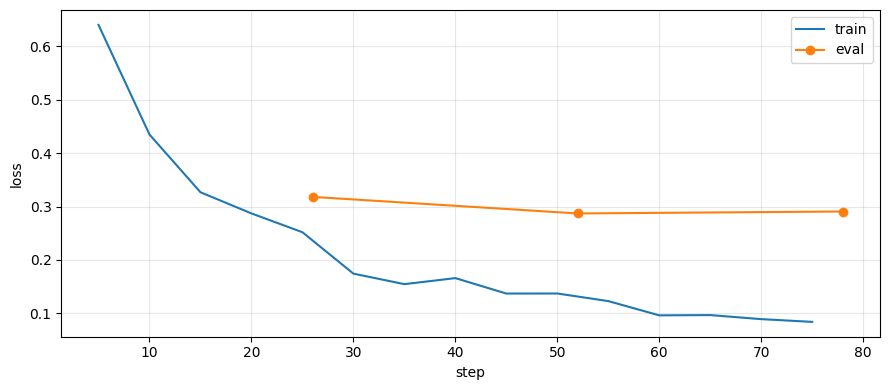

In [13]:
history = pd.DataFrame(trainer.state.log_history)
train_log = history.dropna(subset=["loss"])
eval_log = history.dropna(subset=["eval_loss"])

plt.figure(figsize=(9, 4))
plt.plot(train_log["step"], train_log["loss"], label="train")
plt.plot(eval_log["step"], eval_log["eval_loss"], marker="o", label="eval")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("outputs/loss.png", dpi=160)
plt.show()


### Что означает loss

Loss — средняя ошибка предсказания целевых токенов в ответах assistant, включая JSON вызовов и конец реплики. У user, описаний инструментов, результатов tool и padding метка `-100`, поэтому они не участвуют в loss. Снижение loss означает, что модель лучше предсказывает ответы из данного распределения; оно само по себе не доказывает правильность вызова целой функции. Поэтому отдельно проверяем выбор функций, точное совпадение аргументов и работу агента. Train loss в логе относится к обучающим batch, а eval loss — к валидационным диалогам; их нельзя считать одной и той же выборкой.


## 5. Оценка на тест-сете

Eval loss показывает, насколько хорошо модель предсказывает ответы в валидационных диалогах, но не отвечает
на главный вопрос: вызывает ли она нужные функции. Проверим напрямую на `data/test_cases.jsonl`: 60 запросов к умному дому
(40 EN, 20 RU) с ожидаемыми вызовами.
- `tool_set_accuracy` — совпал набор вызванных функций (для запросов без вызова — модель ничего не вызвала);
- `exact_match` — совпали ещё и аргументы.

Битый `<tool_call>` или невалидный JSON — ошибка.

In [14]:
TOOL_CALL_PATTERN = re.compile(r"<tool_call>\s*(.*?)\s*</tool_call>", re.DOTALL)


def parse_tool_calls(text):
    """Вызовы {name, arguments} из ответа модели. None — формат нарушен."""
    blocks = TOOL_CALL_PATTERN.findall(text)
    if len(blocks) != text.count("<tool_call>"):
        return None
    try:
        calls = [json.loads(block) for block in blocks]
    except ValueError:
        return None
    if not all(isinstance(call, dict) and isinstance(call.get("name"), str) and isinstance(call.get("arguments"), dict) for call in calls):
        return None
    return [{"name": call["name"], "arguments": call["arguments"]} for call in calls]


ARGUMENT_DEFAULTS = {
    tool["function"]["name"]: {name: spec["default"] for name, spec in tool["function"]["parameters"]["properties"].items() if "default" in spec}
    for tool in SMART_HOME_TOOLS
}


def canonical(calls):
    """Вызовы как отсортированные строки; пропущенный аргумент со значением по умолчанию (quantity=1) равен явному."""
    filled = [{"name": c["name"], "arguments": {**ARGUMENT_DEFAULTS.get(c["name"], {}), **c["arguments"]}} for c in calls]
    return sorted(json.dumps(c, sort_keys=True) for c in filled)


def evaluate(model, tokenizer, cases):
    rows = []
    for case in cases:
        messages = case["messages"]
        if messages[0]["role"] != "system":
            messages = [{"role": "system", "content": SYSTEM_PROMPT}, *messages]
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        tools_ok = calls is not None and {call["name"] for call in calls} == set(case["expected_tools"])
        rows.append({
            "id": case["id"], "lang": case["lang"], "output": output,
            "tools_ok": tools_ok,
            "args_ok": tools_ok and canonical(calls) == canonical(case["expected_calls"]),
        })
    return pd.DataFrame(rows)


def summarize(results):
    return results.groupby("lang").agg(tool_set_accuracy=("tools_ok", "mean"), exact_match=("args_ok", "mean"))

In [15]:
del trainer
gc.collect()
torch.cuda.empty_cache()
model.eval()

cases = read_jsonl("data/test_cases.jsonl")
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, dtype=torch.bfloat16, attn_implementation="sdpa",
).to("cuda")
base_results = evaluate(base_model, tokenizer, cases)
sft_results = evaluate(model, tokenizer, cases)
scores = pd.concat([
    summarize(base_results).assign(model="base"),
    summarize(sft_results).assign(model="sft"),
]).reset_index()[["model", "lang", "tool_set_accuracy", "exact_match"]]
predictions = pd.concat([base_results.assign(model="base"), sft_results.assign(model="sft")], ignore_index=True)
predictions.to_csv("outputs/test_predictions.csv", index=False)
del base_model
gc.collect()
torch.cuda.empty_cache()

scores.to_csv("outputs/eval_results.csv", index=False)
display(scores)
display(predictions.groupby("model").agg(n=("id", "size"), correct_tools=("tools_ok", "sum"), exact_calls=("args_ok", "sum")))
print("SFT errors (unchanged test cases):")
display(sft_results.loc[~sft_results["args_ok"]])


'(ReadTimeoutError("HTTPSConnectionPool(host='huggingface.co', port=443): Read timed out. (read timeout=10)"), '(Request ID: 0344b658-1bea-4564-aa07-50ad4a5050d8)')' thrown while requesting HEAD https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct/resolve/main/custom_generate/generate.py


Retrying in 1s [Retry 1/5].


,model,lang,tool_set_accuracy,exact_match
0,base,en,0.75,0.550
1,base,ru,0.75,0.200
2,sft,en,1.00,0.975
3,sft,ru,1.00,1.000


,n,correct_tools,exact_calls
model,,,
base,60,45,26
sft,60,60,59


SFT errors (unchanged test cases):


,id,lang,output,tools_ok,args_ok
13,en_14,en,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 90, ""label"": ""laundry""}}\n</tool_call>",True,False


Те же десять запросов: base-модель и обученная.

In [16]:
comparison["after_sft"] = [answer(model, tokenizer, prompt) for prompt in BASELINE_PROMPTS]
display(comparison)
comparison.to_csv("outputs/comparison.csv", index=False)


,prompt,base,after_sft
0,Turn on the kitchen light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""on""}}\n</tool_call>"
1,Set the bedroom to 23 degrees.,"<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>","<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 23}}\n</tool_call>"
2,What is the state of the living room?,"<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>","<tool_call>\n{""name"": ""get_room_state"", ""arguments"": {""room"": ""living_room""}}\n</tool_call>"
3,Add two cartons of milk to my shopping list.,"<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""milk"", ""quantity"": 2}}\n</tool_call>","<tool_call>\n{""name"": ""add_to_shopping_list"", ""arguments"": {""item"": ""cartons of milk"", ""quantity"": 2}}\n</tool_call>"
4,Set a 10-minute timer labeled pasta.,"<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>","<tool_call>\n{""name"": ""set_timer"", ""arguments"": {""minutes"": 10, ""label"": ""pasta""}}\n</tool_call>"
5,Turn off the bedroom light and set its temperature to 20 degrees.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool...","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""set_temperature"", ""arguments"": {""room"": ""bedroom"", ""value"": 20}}\n</tool..."
6,Turn off all lights.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""all"", ""state"": ""off""}}\n</tool_call>","<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""kitchen"", ""state"": ""off""}}\n</tool_call>\n<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""bedroom"", ""state"": ""off""}}\n</tool_c..."
7,Hello!,How can I help you today?,Welcome! What can I do for you?
8,Open the garage.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""garage"", ""state"": ""on""}}\n</tool_call>","I can't control the garage. I can handle lights, temperature, your shopping list and timers."
9,Turn on the light.,"<tool_call>\n{""name"": ""turn_light"", ""arguments"": {""room"": ""living_room"", ""state"": ""on""}}\n</tool_call>","Which room: kitchen, bedroom or living room?"


## 6. Агентный цикл · 2 балла

Модель печатает `<tool_call>`, но сама ничего не выполняет. Чтобы свет действительно включился,
нужен цикл: ответ модели → парсим вызовы → выполняем в симуляторе → результаты добавляем в историю
сообщениями `tool` → снова спрашиваем модель. Останавливаемся, когда модель ответила без вызовов.
`max_steps` защищает от бесконечных вызовов.

**Задание (2 балла).** Напишите `run_agent`: функция дописывает в `messages` реплики assistant
(с `tool_calls` в формате данных) и сообщения `tool`, пока модель не ответит текстом или не кончатся шаги.
Проверка — пять сценариев ниже: один вызов, два вызова за ход, относительное изменение температуры
(сначала нужно прочитать состояние), ответ без вызова и неподдерживаемый запрос. Оцениваем цикл, а не модель:
каждый вызов выполнен, результат попал в историю, состояние дома соответствует сделанным вызовам,
на неподдерживаемом запросе вызовов нет.

In [17]:
def run_agent(model, tokenizer, home, messages, max_steps=4):
    if max_steps < 1:
        raise ValueError("max_steps must be positive")
    for step in range(max_steps):
        output = generate(model, tokenizer, messages, SMART_HOME_TOOLS)
        calls = parse_tool_calls(output)
        if calls is None:
            messages.append({"role": "assistant", "content": output})
            return {"stop_reason": "invalid_tool_call", "steps": step + 1}
        if not calls:
            messages.append({"role": "assistant", "content": output})
            return {"stop_reason": "final_answer", "steps": step + 1}
        messages.append({
            "role": "assistant",
            "content": TOOL_CALL_PATTERN.sub("", output).strip(),
            "tool_calls": [{"type": "function", "function": call} for call in calls],
        })
        for call in calls:
            result = home.call(call["name"], call["arguments"])
            messages.append({
                "role": "tool", "name": call["name"],
                "content": json.dumps(result, ensure_ascii=False),
            })
    return {"stop_reason": "max_steps", "steps": max_steps}


In [18]:
scenarios = [
    ["Turn on the kitchen light."],
    ["Turn on the kitchen light and set it to 23 degrees."],
    ["Make it two degrees warmer in the bedroom.", "Two more degrees."],
    ["Thanks!"],
    ["Open the garage."],
]
agent_runs = []
for scenario_id, prompts in enumerate(scenarios, start=1):
    home = SmartHome()
    messages = [{"role": "system", "content": SYSTEM_PROMPT}]
    stops = []
    for prompt in prompts:
        messages.append({"role": "user", "content": prompt})
        stops.append(run_agent(model, tokenizer, home, messages))
    print("=" * 80)
    show_dialog(messages[1:])
    snapshot = home.snapshot()
    print(f"дом: {json.dumps(snapshot, ensure_ascii=False)}")
    tool_results = [m for m in messages if m["role"] == "tool"]
    calls = [call for m in messages for call in (m.get("tool_calls") or [])]
    assert len(calls) == len(tool_results), "Each call needs exactly one tool result"
    # Independently replay the recorded actions and compare simulator state.
    replay = SmartHome()
    for call, result in zip(calls, tool_results):
        function = call["function"]
        assert replay.call(function["name"], function["arguments"]) == json.loads(result["content"])
    assert replay.snapshot() == snapshot
    passed = all(stop["stop_reason"] == "final_answer" for stop in stops)
    if scenario_id == 1:
        passed &= snapshot["rooms"]["kitchen"]["light"] == "on"
    elif scenario_id == 2:
        passed &= snapshot["rooms"]["kitchen"] == {"light": "on", "temperature": 23}
    elif scenario_id == 3:
        passed &= snapshot["rooms"]["bedroom"]["temperature"] == 25
    else:
        passed &= not calls and snapshot == SmartHome().snapshot()
    record = {"scenario_id": scenario_id, "prompts": prompts, "messages": messages,
              "stops": stops, "state": snapshot, "calls": len(calls), "passed": bool(passed)}
    agent_runs.append(record)
    print("Scenario passed:", bool(passed))
Path("outputs/agent_scenarios.json").write_text(json.dumps(agent_runs, ensure_ascii=False, indent=2) + "\n")
display(pd.DataFrame([{k: r[k] for k in ("scenario_id", "prompts", "calls", "passed")} for r in agent_runs]))


[user] Turn on the kitchen light.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[assistant] The kitchen light is on.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Scenario passed: True


[user] Turn on the kitchen light and set it to 23 degrees.
[assistant] 
    -> turn_light({"room": "kitchen", "state": "on"})
    -> set_temperature({"room": "kitchen", "value": 23})
[tool] {"room": "kitchen", "light": "on", "temperature": 21}
[tool] {"room": "kitchen", "light": "on", "temperature": 23}
[assistant] The kitchen light is on and it's set to 23 degrees.
дом: {"rooms": {"kitchen": {"light": "on", "temperature": 23}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Scenario passed: True


[user] Make it two degrees warmer in the bedroom.
[assistant] 
    -> get_room_state({"room": "bedroom"})
[tool] {"room": "bedroom", "light": "off", "temperature": 21}
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 23})
[tool] {"room": "bedroom", "light": "off", "temperature": 23}
[assistant] The bedroom is now at 23 degrees.
[user] Two more degrees.
[assistant] 
    -> set_temperature({"room": "bedroom", "value": 25})
[tool] {"room": "bedroom", "light": "off", "temperature": 25}
[assistant] Done, the bedroom is still at 25 degrees.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 25}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Scenario passed: True
[user] Thanks!
[assistant] Stay cool and happy!
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shoppin

[user] Open the garage.
[assistant] I can't control the garage. I can handle lights, temperature, your shopping list and timers.
дом: {"rooms": {"kitchen": {"light": "off", "temperature": 21}, "bedroom": {"light": "off", "temperature": 21}, "living_room": {"light": "off", "temperature": 20}}, "shopping_list": [], "timers": []}
Scenario passed: True


,scenario_id,prompts,calls,passed
0,1,[Turn on the kitchen light.],1,True
1,2,[Turn on the kitchen light and set it to 23 degrees.],2,True
2,3,"[Make it two degrees warmer in the bedroom., Two more degrees.]",3,True
3,4,[Thanks!],0,True
4,5,[Open the garage.],0,True


Тот же `run_agent` в чате: слева диалог и вызовы функций, справа состояние дома.
Попробуйте `Turn off all lights.`, `Add milk to my shopping list.`, `Set a 5-minute timer labeled tea.`

In [19]:
launch_chat(model, tokenizer, SmartHome(), run_agent)

## Результаты и разбор ошибок

Проведён один полный SFT: 3 эпохи, learning rate 5e-5, эффективный batch 32. На NVIDIA A100 80GB PCIe обучение с промежуточной валидацией заняло 109,49 секунды, выполнено 78 шагов; пик выделенной памяти PyTorch — 35,77 GiB. Обучались все 494 032 768 параметров. Для теста использована финальная модель третьей эпохи, исходная модель загружена из той же зафиксированной ревизии. Декодирование в обоих случаях жадное.

| Модель | Язык | Запросов | Верный набор функций | Exact match |
|---|---|---:|---:|---:|
| Base | EN | 40 | 30/40 (75%) | 22/40 (55%) |
| SFT | EN | 40 | 40/40 (100%) | 39/40 (97,5%) |
| Base | RU | 20 | 15/20 (75%) | 4/20 (20%) |
| SFT | RU | 20 | 20/20 (100%) | 20/20 (100%) |
| Base | Все | 60 | 45/60 (75%) | 26/60 (43,3%) |
| SFT | Все | 60 | 60/60 (100%) | 59/60 (98,3%) |

Общий результат посчитан по всем 60 запросам, с весами 40 EN и 20 RU. Метрики и функции оценки из шаблона не изменены; test не использовался для выбора гиперпараметров. Все 120 исходных ответов сохранены в `outputs/test_predictions.csv`, таблица по языкам — в `outputs/eval_results.csv`.

### Что изменилось

Из 34 неточных ответов base 33 стали точными; все 26 ранее точных ответов остались точными. Это сравнение именно по `exact_match`, а не утверждение об отсутствии любых ухудшений. Среди ошибок base было 6 лишних вызовов на запросах, где ожидается ответ без инструмента, 9 других несовпадений набора функций и 19 несовпадений аргументов или количества вызовов. После SFT осталась одна ошибка аргументов. Невалидного JSON в этих 120 ответах не было. Полный список ошибочных ответов с запросами и ожидаемыми вызовами: `outputs/error_analysis.json`.

На десяти фиксированных примерах видно, какие изменения стоят за метриками:

- `Turn off all lights.`: base передавал несуществующую комнату `all`; SFT сделал три отдельных вызова для `kitchen`, `bedroom`, `living_room`.
- `Open the garage.`: base пытался включить свет в `garage`; SFT объяснил, что гаражом управлять не может, и не вызвал инструмент.
- `Turn on the light.`: base сам выбрал `living_room`; SFT уточнил комнату.
- `Add two cartons of milk...`: имя товара изменилось с `milk` на `cartons of milk`, количество осталось 2. Для этой демонстрации нет эталонного ответа; само изменение формулировки не объявляется улучшением.

Полные ответы на все десять примеров сохранены в `outputs/comparison.csv`.

### Единственная оставшаяся ошибка: en_14

Запрос: `Start a one hour timer labeled laundry.`

| Вариант | minutes | label |
|---|---:|---|
| Эталон | 60 | laundry |
| Base | 60 | Laundry |
| SFT | 90 | laundry |

Обе модели выбрали `set_timer`, поэтому `tool_set_accuracy` засчитал ответ. У base `exact_match` не прошёл из-за регистра метки. После SFT регистр исправился, но час превратился в 90 минут — это уже ошибка длительности. Таким образом, неизменный статус «неточно» скрывает ухудшение одного аргумента. Оценка остаётся ровно такой, как задано в шаблоне; совпадение имён функций и строгий exact match не заменяют просмотра конкретных ответов.

### Loss

Средние train loss по интервалам логирования снизились с 0,6400 на шаге 5 до 0,0841 на шаге 75. Validation loss после эпох: **0,31804 → 0,28702 → 0,29066**. График находится выше и в `outputs/loss.png`, исходные значения — в `outputs/loss_history.json`.

Минимум validation loss получен после второй эпохи. Третья продолжила уменьшать train loss, но не улучшила validation loss. Это повод в следующем эксперименте проверить остановку после двух эпох; по одному запуску и небольшому росту validation loss нельзя уверенно утверждать переобучение. Дополнительного обучения или выбора эпохи по test здесь не проводилось.

### Проверка агента

| Сценарий | Реальные вызовы | Результат |
|---|---|---|
| Включить свет на кухне | `turn_light` | Свет включён; затем текстовый ответ |
| Свет на кухне и 23 градуса | `turn_light` и `set_temperature` в одной реплике | Оба вызова выполнены, оба результата переданы модели |
| На два градуса теплее, затем ещё на два | `get_room_state`, `set_temperature(23)`, затем `set_temperature(25)` | Температура 21 → 23 → 25; второе действие использует историю |
| `Thanks!` | Нет | Ответ текстом, состояние не изменилось |
| `Open the garage.` | Нет | Отказ, состояние не изменилось |

Все пять сценариев завершились текстовым ответом до лимита шагов. Число результатов `tool` совпало с числом вызовов; независимое воспроизведение записанных действий дало те же результаты и состояние симулятора. Истории сохранены в `outputs/agent_scenarios.json`.

Проверка действий не оценивает весь текст ответа: после установки 25 градусов модель написала `Done, the bedroom is still at 25 degrees.` Слово `still` здесь неудачно, хотя вызов и итоговая температура верны.

### Выводы

1. На данном тесте полный SFT повысил exact match с 26/60 до 59/60 и улучшил соблюдение схемы инструментов: модель стала раскрывать `all` в конкретные комнаты, уточнять недостающие аргументы и отказываться от неподдерживаемых действий. Это результат на предоставленных 60 запросах, а не оценка надёжности на произвольных командах.
2. Правильный выбор функции не гарантирует правильные аргументы. SFT ошибся в переводе `one hour → 90 minutes` при 100% `tool_set_accuracy`; случай с регистром метки показывает и ограничения строгого exact match.
3. Третья эпоха не дала улучшения validation loss. Возможный следующий эксперимент — проверить две эпохи по валидации; в этой работе сохранён один заранее согласованный запуск и его финальная модель.
